# Zero-Forcing and MMSE Equalization

## Objective

The previous experiment introduced additive white Gaussian noise (AWGN) into a frequency-selective OFDM channel and used zero-forcing (ZF) equalization at the receiver.

For each subcarrier,

$$
Y[k] = H[k]X[k] + W[k],
$$

where

- $X[k]$ is the transmitted QPSK symbol,
- $H[k]$ is the channel frequency response,
- $W[k]$ is additive complex Gaussian noise, and
- $Y[k]$ is the received subcarrier symbol.

Zero-forcing equalization estimates the transmitted symbol using

$$
\hat{X}_{\mathrm{ZF}}[k] = \frac{Y[k]}{H[k]}.
$$

Although this removes the deterministic channel distortion when $H[k]$ is known, it can strongly amplify noise on subcarriers for which $|H[k]|$ is small.

This notebook compares zero-forcing equalization with minimum mean-square error (MMSE) equalization.

The goals are to:

1. Reproduce the QPSK/OFDM transmitter and frequency-selective multipath channel.
2. Add complex AWGN over a range of sample-domain SNR values.
3. Recover the received OFDM symbols using both ZF and MMSE equalization.
4. Compare the equalized constellations.
5. Measure BER for both equalizers over the same channel and noise realizations.
6. Examine how weak channel subcarriers cause noise enhancement under ZF.
7. Compare the symbol-estimation error of ZF and MMSE and explain why their hard-decision QPSK BER can be identical under perfect channel knowledge.

Perfect knowledge of the channel response is assumed in this experiment so that the effect of the equalizer itself can be isolated. Channel-estimation error is left as a possible future extension so that the present experiment can isolate the behavior of the equalizers themselves.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# OFDM parameters
N_fft = 64
N_cp = 16

# QPSK carries two bits per symbol
bits_per_qpsk_symbol = 2

# Use enough data for stable BER estimates while filling complete OFDM symbols
num_bits = 131_072

bits_per_ofdm_symbol = bits_per_qpsk_symbol * N_fft

assert num_bits % bits_per_ofdm_symbol == 0

num_qpsk_symbols = num_bits // bits_per_qpsk_symbol
num_ofdm_symbols = num_qpsk_symbols // N_fft

print("FFT size:", N_fft)
print("Cyclic-prefix length:", N_cp)
print("Bits per QPSK symbol:", bits_per_qpsk_symbol)
print("Bits per OFDM symbol:", bits_per_ofdm_symbol)
print("Total transmitted bits:", num_bits)
print("QPSK symbols:", num_qpsk_symbols)
print("OFDM symbols:", num_ofdm_symbols)

FFT size: 64
Cyclic-prefix length: 16
Bits per QPSK symbol: 2
Bits per OFDM symbol: 128
Total transmitted bits: 131072
QPSK symbols: 65536
OFDM symbols: 1024


## QPSK/OFDM Transmitter

A reproducible binary sequence is mapped to normalized QPSK symbols using the same Gray-coded constellation used in the previous experiments.

The Gray-coded mapping used throughout this project is

$$
00 \rightarrow \frac{1+j}{\sqrt{2}},
$$

$$
01 \rightarrow \frac{1-j}{\sqrt{2}},
$$

$$
11 \rightarrow \frac{-1-j}{\sqrt{2}},
$$

$$
10 \rightarrow \frac{-1+j}{\sqrt{2}}.
$$

Each QPSK symbol therefore has unit energy.

The symbols are arranged into blocks of 64 frequency-domain subcarriers. A 64-point inverse fast Fourier transform (IFFT) converts each block to the time domain, and a 16-sample cyclic prefix is prepended to each OFDM symbol.

As in the previous notebooks, all 64 FFT bins are treated as data-bearing subcarriers. This simplified allocation allows the equalization methods to be compared directly before pilot-based channel estimation is introduced.

In [2]:
# Generate reproducible binary data
data_rng = np.random.default_rng(42)

bits = data_rng.integers(
    low=0,
    high=2,
    size=num_bits
)

# Group bits into pairs
bit_pairs = bits.reshape(-1, 2)

# Gray-coded normalized QPSK mapping
I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

# Organize QPSK symbols into frequency-domain OFDM blocks
ofdm_frequency_symbols = qpsk_symbols.reshape(
    num_ofdm_symbols,
    N_fft
)

# Convert each OFDM symbol to the time domain
ofdm_time_symbols = np.fft.ifft(
    ofdm_frequency_symbols,
    axis=1
)

# Add cyclic prefix
cyclic_prefix = ofdm_time_symbols[:, -N_cp:]

ofdm_with_cp = np.concatenate(
    (cyclic_prefix, ofdm_time_symbols),
    axis=1
)

# Serialize all OFDM blocks
tx_serial = ofdm_with_cp.reshape(-1)

block_length = N_fft + N_cp

print("Binary-data shape:", bits.shape)
print("QPSK-symbol shape:", qpsk_symbols.shape)
print("Frequency-domain OFDM shape:", ofdm_frequency_symbols.shape)
print("Time-domain OFDM shape:", ofdm_time_symbols.shape)
print("OFDM-with-CP shape:", ofdm_with_cp.shape)
print("Serialized waveform length:", len(tx_serial))
print(
    "Average QPSK symbol energy:",
    f"{np.mean(np.abs(qpsk_symbols) ** 2):.6f}"
)

# Sanity checks
assert bits.shape == (131_072,)
assert qpsk_symbols.shape == (65_536,)
assert ofdm_frequency_symbols.shape == (1024, 64)
assert ofdm_time_symbols.shape == (1024, 64)
assert ofdm_with_cp.shape == (1024, 80)
assert len(tx_serial) == 81_920

assert np.allclose(
    np.mean(np.abs(qpsk_symbols) ** 2),
    1.0
)

Binary-data shape: (131072,)
QPSK-symbol shape: (65536,)
Frequency-domain OFDM shape: (1024, 64)
Time-domain OFDM shape: (1024, 64)
OFDM-with-CP shape: (1024, 80)
Serialized waveform length: 81920
Average QPSK symbol energy: 1.000000


## Frequency-Selective Multipath Channel

The transmitted OFDM waveform is passed through the same three-path frequency-selective channel used in the previous experiments.

Before normalization, the nonzero channel coefficients are

$$
h[0] = 1,
$$

$$
h[3] = 0.45e^{j0.6},
$$

and

$$
h[8] = 0.25e^{-j0.9}.
$$

The impulse response is normalized so that

$$
\sum_{\ell}|h[\ell]|^2 = 1.
$$

Because the maximum path delay is 8 samples and the cyclic prefix contains 16 samples,

$$
N_{\mathrm{CP}} \geq L_h - 1,
$$

so the cyclic prefix is long enough to prevent intersymbol interference from contaminating the useful portion of each OFDM symbol.

The 64-point channel frequency response is

$$
H[k] = \sum_{\ell=0}^{L_h-1} h[\ell]e^{-j2\pi k\ell/N},
$$

where $N=64$.

This response will be assumed to be known perfectly so that the behavior of the ZF and MMSE equalizers can be compared independently of channel-estimation error.

In [3]:
# Three-path complex baseband multipath channel
h = np.zeros(9, dtype=complex)

h[0] = 1.0
h[3] = 0.45 * np.exp(1j * 0.6)
h[8] = 0.25 * np.exp(-1j * 0.9)

# Normalize channel to unit total energy
h = h / np.sqrt(np.sum(np.abs(h) ** 2))

channel_energy = np.sum(np.abs(h) ** 2)
max_channel_delay = len(h) - 1

# Channel frequency response at the OFDM subcarriers
H = np.fft.fft(h, n=N_fft)
H_magnitude = np.abs(H)

print("Channel impulse-response length:", len(h))
print("Maximum channel delay:", max_channel_delay, "samples")
print("Cyclic-prefix length:", N_cp, "samples")
print("Normalized channel energy:", channel_energy)
print("Minimum subcarrier magnitude:", f"{np.min(H_magnitude):.4f}")
print("Maximum subcarrier magnitude:", f"{np.max(H_magnitude):.4f}")

# Validation
assert N_cp >= max_channel_delay
assert np.allclose(channel_energy, 1.0)
assert np.all(H_magnitude > 0)

Channel impulse-response length: 9
Maximum channel delay: 8 samples
Cyclic-prefix length: 16 samples
Normalized channel energy: 0.9999999999999996
Minimum subcarrier magnitude: 0.3156
Maximum subcarrier magnitude: 1.5078


## Clean Multipath Received Signal

Before adding noise, the serialized OFDM waveform is passed through the multipath channel to create a clean received reference.

The discrete-time received signal is

$$
y[n] = \sum_{\ell=0}^{L_h-1} h[\ell]x[n-\ell].
$$

The clean received waveform serves two purposes:

1. it verifies that the transmitter, channel, and receiver remain internally consistent, and
2. its average sample power provides the reference used to define the sample-domain SNR when AWGN is added.

The convolution produces a short channel tail after the final transmitted sample. Only the samples corresponding to the transmitted OFDM stream are retained for receiver processing.

In [4]:
# Pass serialized OFDM waveform through the multipath channel
clean_rx_full = np.convolve(
    tx_serial,
    h,
    mode="full"
)

# Retain samples corresponding to the transmitted OFDM stream
clean_rx_serial = clean_rx_full[:len(tx_serial)]

# Average received complex-sample power
clean_rx_power = np.mean(np.abs(clean_rx_serial) ** 2)

print("Transmitted sample count:", len(tx_serial))
print("Full convolution sample count:", len(clean_rx_full))
print("Retained received sample count:", len(clean_rx_serial))
print("Average clean received sample power:", f"{clean_rx_power:.8f}")

assert len(clean_rx_serial) == len(tx_serial)
assert clean_rx_power > 0

Transmitted sample count: 81920
Full convolution sample count: 81928
Retained received sample count: 81920
Average clean received sample power: 0.01564021


## Noiseless Receiver Validation

Before introducing AWGN and comparing the equalizers, the clean multipath signal is processed through the OFDM receiver.

Each received 80-sample block consists of a 16-sample cyclic prefix followed by 64 useful samples. After cyclic-prefix removal, a 64-point fast Fourier transform (FFT) returns the signal to the frequency domain.

Because the cyclic prefix is longer than the maximum channel delay, the noiseless received subcarrier symbols should satisfy

$$
Y[k] = H[k]X[k].
$$

Verifying this relationship confirms that the transmitter, multipath channel, cyclic-prefix processing, and receiver FFT are internally consistent before noise and equalization are introduced.

In [5]:
# Reshape the clean received serial stream into OFDM blocks
clean_rx_blocks = clean_rx_serial.reshape(
    num_ofdm_symbols,
    block_length
)

# Remove the cyclic prefix
clean_rx_without_cp = clean_rx_blocks[:, N_cp:]

# Transform the useful samples back to the frequency domain
clean_rx_frequency = np.fft.fft(
    clean_rx_without_cp,
    axis=1
)

# Expected noiseless frequency-domain result: Y[k] = H[k] X[k]
expected_clean_rx_frequency = (
    ofdm_frequency_symbols * H[np.newaxis, :]
)

# Measure numerical agreement
clean_channel_model_error = np.max(
    np.abs(
        clean_rx_frequency
        - expected_clean_rx_frequency
    )
)

print("Received block-array shape:", clean_rx_blocks.shape)
print("Shape after CP removal:", clean_rx_without_cp.shape)
print("Frequency-domain shape:", clean_rx_frequency.shape)
print(
    "Maximum clean-channel model error:",
    f"{clean_channel_model_error:.3e}"
)

assert clean_rx_blocks.shape == (1024, 80)
assert clean_rx_without_cp.shape == (1024, 64)
assert clean_rx_frequency.shape == (1024, 64)

assert np.allclose(
    clean_rx_frequency,
    expected_clean_rx_frequency,
    atol=1e-12
)

Received block-array shape: (1024, 80)
Shape after CP removal: (1024, 64)
Frequency-domain shape: (1024, 64)
Maximum clean-channel model error: 1.024e-15


## Complex AWGN Test Signal

The clean multipath received waveform is now corrupted by additive white Gaussian noise (AWGN).

For a target sample-domain signal-to-noise ratio,

$$
\mathrm{SNR} = \frac{P_s}{P_n},
$$

where $P_s$ is the average power of the clean received complex samples and $P_n$ is the average complex-noise power.

In decibels,

$$
\mathrm{SNR}_{\mathrm{dB}}
=
10\log_{10}\left(\frac{P_s}{P_n}\right).
$$

Therefore,

$$
P_n
=
\frac{P_s}{10^{\mathrm{SNR}_{\mathrm{dB}}/10}}.
$$

Complex AWGN is generated as

$$
n[m]
=
\sqrt{\frac{P_n}{2}}
\left(
n_I[m] + j n_Q[m]
\right),
$$

where \$n_I[m]\$ and \$n_Q[m]\$ are independent zero-mean, unit-variance Gaussian random variables.

A separate random-number generator is used for the noise so that the transmitted data sequence and the noise realization are independently reproducible.

In [6]:
# Add complex AWGN for a requested sample-domain SNR
def add_complex_awgn(signal, snr_db, rng):
    signal_power = np.mean(np.abs(signal) ** 2)

    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power / 2) * (
        rng.standard_normal(signal.shape)
        + 1j * rng.standard_normal(signal.shape)
    )

    noisy_signal = signal + noise

    return noisy_signal, noise, noise_power


# Separate reproducible RNG for noise
noise_rng = np.random.default_rng(2028)

# Initial comparison point
test_snr_db = 10.0

noisy_rx_serial, test_noise, noise_power = add_complex_awgn(
    clean_rx_serial,
    test_snr_db,
    noise_rng
)

measured_noise_power = np.mean(np.abs(test_noise) ** 2)

measured_snr_db = 10 * np.log10(
    clean_rx_power / measured_noise_power
)

# Under NumPy's unnormalized forward FFT, time-domain noise
# variance P_n becomes N_fft * P_n per frequency-domain bin.
frequency_noise_variance = N_fft * noise_power

print("Target sample-domain SNR:", f"{test_snr_db:.2f} dB")
print("Clean received sample power:", f"{clean_rx_power:.8f}")
print("Target time-domain noise power:", f"{noise_power:.8f}")
print("Measured time-domain noise power:", f"{measured_noise_power:.8f}")
print("Measured sample-domain SNR:", f"{measured_snr_db:.3f} dB")
print(
    "Frequency-domain noise variance per subcarrier:",
    f"{frequency_noise_variance:.8f}"
)

assert len(noisy_rx_serial) == len(clean_rx_serial)
assert np.isclose(
    measured_snr_db,
    test_snr_db,
    atol=0.15
)

Target sample-domain SNR: 10.00 dB
Clean received sample power: 0.01564021
Target time-domain noise power: 0.00156402
Measured time-domain noise power: 0.00157358
Measured sample-domain SNR: 9.974 dB
Frequency-domain noise variance per subcarrier: 0.10009734


## Zero-Forcing and MMSE Equalization

After cyclic-prefix removal and the FFT, the noisy received symbol on subcarrier \(k\) is

$$
Y[k] = H[k]X[k] + W[k].
$$

Zero-forcing equalization removes the channel coefficient directly:

$$
\hat{X}_{\mathrm{ZF}}[k]
=
\frac{Y[k]}{H[k]}.
$$

This completely removes the deterministic channel distortion, but it can strongly amplify noise when \(|H[k]|\) is small.

The linear minimum mean-square error (MMSE) equalizer instead uses

$$
G_{\mathrm{MMSE}}[k]
=
\frac{H^*[k]}
{|H[k]|^2 + \sigma_W^2/E_s},
$$

so that

$$
\hat{X}_{\mathrm{MMSE}}[k]
=
G_{\mathrm{MMSE}}[k]Y[k].
$$

Here $E_s$ is the average QPSK-symbol energy and $\sigma_W^2$ is the frequency-domain noise variance.

For NumPy's FFT convention,

$$
\sigma_W^2 = N_{\mathrm{FFT}}P_n.
$$

The same noisy waveform is used for both equalizers so that their estimates can be compared directly.

In [7]:
# Reconstruct received OFDM blocks
noisy_rx_blocks = noisy_rx_serial.reshape(
    num_ofdm_symbols,
    block_length
)

# Remove cyclic prefix
noisy_rx_without_cp = noisy_rx_blocks[:, N_cp:]

# FFT to frequency domain
noisy_rx_frequency = np.fft.fft(
    noisy_rx_without_cp,
    axis=1
)

# ---------------------------
# Zero-Forcing equalization
# ---------------------------
zf_equalized = (
    noisy_rx_frequency
    / H[np.newaxis, :]
)

# ---------------------------
# MMSE equalization
# ---------------------------
symbol_energy = np.mean(np.abs(qpsk_symbols) ** 2)

mmse_gain = (
    np.conj(H)
    /
    (
        np.abs(H) ** 2
        + frequency_noise_variance / symbol_energy
    )
)

mmse_equalized = (
    noisy_rx_frequency
    * mmse_gain[np.newaxis, :]
)

# Normalized symbol-estimation errors
zf_nmse = (
    np.mean(
        np.abs(
            zf_equalized
            - ofdm_frequency_symbols
        ) ** 2
    )
    /
    np.mean(np.abs(ofdm_frequency_symbols) ** 2)
)

mmse_nmse = (
    np.mean(
        np.abs(
            mmse_equalized
            - ofdm_frequency_symbols
        ) ** 2
    )
    /
    np.mean(np.abs(ofdm_frequency_symbols) ** 2)
)

print("Test SNR:", f"{test_snr_db:.2f} dB")
print("ZF normalized MSE:", f"{zf_nmse:.6f}")
print("MMSE normalized MSE:", f"{mmse_nmse:.6f}")
print(
    "MMSE MSE improvement:",
    f"{100 * (1 - mmse_nmse / zf_nmse):.2f}%"
)

assert mmse_nmse < zf_nmse

Test SNR: 10.00 dB
ZF normalized MSE: 0.182038
MMSE normalized MSE: 0.136912
MMSE MSE improvement: 24.79%


## Hard-Decision QPSK BER Comparison

Although MMSE equalization produces a smaller mean-square symbol-estimation error than zero-forcing equalization, this does not necessarily imply a different hard-decision BER in the present experiment.

For zero-forcing,

$$
\hat{X}_{\mathrm{ZF}}[k]
=
\frac{Y[k]}{H[k]}.
$$

The MMSE estimate can be rewritten as

$$
\hat{X}_{\mathrm{MMSE}}[k]
=
\frac{|H[k]|^2}
{|H[k]|^2+\sigma_W^2/E_s}
\hat{X}_{\mathrm{ZF}}[k].
$$

The multiplier

$$
\alpha[k]
=
\frac{|H[k]|^2}
{|H[k]|^2+\sigma_W^2/E_s}
$$

is strictly positive and real.

Therefore, MMSE changes the magnitude of the ZF estimate but does not change its quadrant. Since hard-decision QPSK detection depends only on the signs of the in-phase and quadrature components, both equalizers should produce identical detected bits under perfect channel knowledge.

The following calculation verifies this result directly.

In [8]:
# Flatten equalized OFDM symbols
zf_symbols = zf_equalized.reshape(-1)
mmse_symbols = mmse_equalized.reshape(-1)

# Hard-decision QPSK demodulation: ZF
zf_first_bits = (zf_symbols.real < 0).astype(int)
zf_second_bits = (zf_symbols.imag < 0).astype(int)

zf_bit_pairs = np.column_stack(
    (zf_first_bits, zf_second_bits)
)

zf_recovered_bits = zf_bit_pairs.reshape(-1)

# Hard-decision QPSK demodulation: MMSE
mmse_first_bits = (mmse_symbols.real < 0).astype(int)
mmse_second_bits = (mmse_symbols.imag < 0).astype(int)

mmse_bit_pairs = np.column_stack(
    (mmse_first_bits, mmse_second_bits)
)

mmse_recovered_bits = mmse_bit_pairs.reshape(-1)

# Calculate BER
zf_bit_errors = np.count_nonzero(
    bits != zf_recovered_bits
)

mmse_bit_errors = np.count_nonzero(
    bits != mmse_recovered_bits
)

zf_ber = zf_bit_errors / len(bits)
mmse_ber = mmse_bit_errors / len(bits)

# Compare the decisions made by the two equalizers
decision_differences = np.count_nonzero(
    zf_recovered_bits != mmse_recovered_bits
)

print("Total transmitted bits:", len(bits))
print()
print("ZF bit errors:", zf_bit_errors)
print("ZF BER:", f"{zf_ber:.8f}")
print()
print("MMSE bit errors:", mmse_bit_errors)
print("MMSE BER:", f"{mmse_ber:.8f}")
print()
print(
    "Different hard decisions between ZF and MMSE:",
    decision_differences
)

assert np.array_equal(
    zf_recovered_bits,
    mmse_recovered_bits
)

Total transmitted bits: 131072

ZF bit errors: 2197
ZF BER: 0.01676178

MMSE bit errors: 2197
MMSE BER: 0.01676178

Different hard decisions between ZF and MMSE: 0


In [9]:
# MMSE is a positive real scaling of the ZF estimate
mmse_scale = (
    np.abs(H) ** 2
    /
    (
        np.abs(H) ** 2
        + frequency_noise_variance / symbol_energy
    )
)

mmse_scaling_error = np.max(
    np.abs(
        mmse_equalized
        - zf_equalized * mmse_scale[np.newaxis, :]
    )
)

print(
    "Minimum MMSE scaling factor:",
    f"{np.min(mmse_scale):.6f}"
)

print(
    "Maximum MMSE scaling factor:",
    f"{np.max(mmse_scale):.6f}"
)

print(
    "Maximum MMSE/ZF scaling identity error:",
    f"{mmse_scaling_error:.3e}"
)

assert np.all(mmse_scale > 0)
assert mmse_scaling_error < 1e-12

Minimum MMSE scaling factor: 0.498806
Maximum MMSE scaling factor: 0.957826
Maximum MMSE/ZF scaling identity error: 9.155e-16


## ZF and MMSE Constellation Comparison

The previous calculations showed that MMSE equalization produces a lower symbol-estimation error than zero-forcing equalization, even though both methods produce the same hard QPSK decisions in this experiment.

This can be seen directly in the equalized constellations.

Zero-forcing attempts to restore the transmitted QPSK symbols exactly by dividing by the channel response. On weak subcarriers, this can greatly amplify noise.

MMSE instead trades perfect channel inversion for reduced noise enhancement. As a result, its estimates are generally pulled somewhat toward the origin, especially on subcarriers with small channel magnitude.

Because the MMSE scaling factor is positive and real, however, the symbol quadrant is unchanged relative to ZF. Therefore the hard-decision QPSK bits remain identical under the assumptions of this experiment.

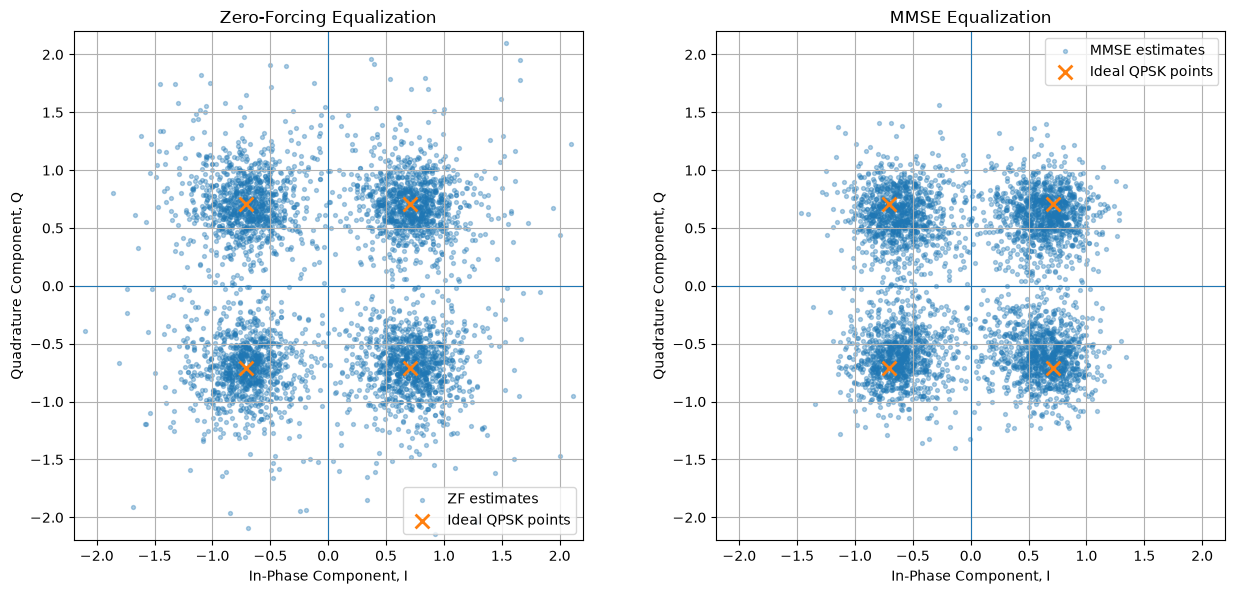

In [10]:
# Ideal QPSK constellation points
ideal_qpsk_points = np.array([
    1 + 1j,
    1 - 1j,
    -1 - 1j,
    -1 + 1j
]) / np.sqrt(2)

# Plot a manageable subset so the constellation remains readable
num_plot_symbols = 4000

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# -------------------------
# ZF constellation
# -------------------------
axes[0].scatter(
    zf_symbols[:num_plot_symbols].real,
    zf_symbols[:num_plot_symbols].imag,
    s=8,
    alpha=0.35,
    label="ZF estimates"
)

axes[0].scatter(
    ideal_qpsk_points.real,
    ideal_qpsk_points.imag,
    marker="x",
    s=100,
    linewidths=2,
    label="Ideal QPSK points"
)

axes[0].axhline(0, linewidth=0.8)
axes[0].axvline(0, linewidth=0.8)
axes[0].set_xlim(-2.2, 2.2)
axes[0].set_ylim(-2.2, 2.2)
axes[0].set_xlabel("In-Phase Component, I")
axes[0].set_ylabel("Quadrature Component, Q")
axes[0].set_title("Zero-Forcing Equalization")
axes[0].grid(True)
axes[0].legend()
axes[0].set_aspect("equal", adjustable="box")

# -------------------------
# MMSE constellation
# -------------------------
axes[1].scatter(
    mmse_symbols[:num_plot_symbols].real,
    mmse_symbols[:num_plot_symbols].imag,
    s=8,
    alpha=0.35,
    label="MMSE estimates"
)

axes[1].scatter(
    ideal_qpsk_points.real,
    ideal_qpsk_points.imag,
    marker="x",
    s=100,
    linewidths=2,
    label="Ideal QPSK points"
)

axes[1].axhline(0, linewidth=0.8)
axes[1].axvline(0, linewidth=0.8)
axes[1].set_xlim(-2.2, 2.2)
axes[1].set_ylim(-2.2, 2.2)
axes[1].set_xlabel("In-Phase Component, I")
axes[1].set_ylabel("Quadrature Component, Q")
axes[1].set_title("MMSE Equalization")
axes[1].grid(True)
axes[1].legend()
axes[1].set_aspect("equal", adjustable="box")

plt.tight_layout()

plt.savefig(
    "../results/zf_mmse_constellation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## ZF and MMSE Performance Versus SNR

A single 10 dB realization demonstrated the difference between zero-forcing and MMSE equalization. The comparison is now repeated over a range of sample-domain SNR values.

For every SNR point, the same transmitted OFDM waveform and multipath channel are used. The same AWGN realization is also supplied to both equalizers, ensuring a fair paired comparison.

Two performance metrics are evaluated:

1. **Normalized mean-square symbol-estimation error (NMSE)**, which measures how accurately the transmitted complex QPSK symbols are reconstructed.
2. **Bit error rate (BER)**, which measures the accuracy of the final hard QPSK decisions.

Under perfect channel knowledge and the present QPSK detector, ZF and MMSE are expected to have identical hard-decision BER because MMSE is a positive real scaling of the ZF estimate. Their NMSE values, however, need not be equal.

MMSE should provide its largest NMSE advantage at low and moderate SNR, where suppressing noise enhancement is most valuable. As SNR becomes large, the MMSE equalizer approaches the zero-forcing equalizer.

In [11]:
snr_db_values = np.arange(0, 22, 2)
num_trials = 5

sweep_rng = np.random.default_rng(2029)

zf_nmse_values = []
mmse_nmse_values = []

zf_ber_values = []
mmse_ber_values = []

for snr_db in snr_db_values:

    zf_error_energy = 0.0
    mmse_error_energy = 0.0
    symbol_energy_total = 0.0

    zf_bit_errors_total = 0
    mmse_bit_errors_total = 0
    total_bits_tested = 0

    for _ in range(num_trials):

        # --------------------------------
        # Generate the SAME noisy waveform
        # for both equalizers
        # --------------------------------
        noisy_signal, _, noise_power = add_complex_awgn(
            clean_rx_serial,
            snr_db,
            sweep_rng
        )

        # Reconstruct OFDM blocks
        noisy_blocks = noisy_signal.reshape(
            num_ofdm_symbols,
            block_length
        )

        # Remove cyclic prefix
        noisy_without_cp = noisy_blocks[:, N_cp:]

        # FFT to frequency domain
        noisy_frequency = np.fft.fft(
            noisy_without_cp,
            axis=1
        )

        # Frequency-domain noise variance
        frequency_noise_variance_trial = (
            N_fft * noise_power
        )

        # -------------------------
        # ZF
        # -------------------------
        zf_trial = (
            noisy_frequency
            / H[np.newaxis, :]
        )

        # -------------------------
        # MMSE
        # -------------------------
        mmse_gain_trial = (
            np.conj(H)
            /
            (
                np.abs(H) ** 2
                + frequency_noise_variance_trial / symbol_energy
            )
        )

        mmse_trial = (
            noisy_frequency
            * mmse_gain_trial[np.newaxis, :]
        )

        # -------------------------
        # NMSE accumulation
        # -------------------------
        zf_error_energy += np.sum(
            np.abs(
                zf_trial - ofdm_frequency_symbols
            ) ** 2
        )

        mmse_error_energy += np.sum(
            np.abs(
                mmse_trial - ofdm_frequency_symbols
            ) ** 2
        )

        symbol_energy_total += np.sum(
            np.abs(ofdm_frequency_symbols) ** 2
        )

        # -------------------------
        # ZF hard decisions
        # -------------------------
        zf_trial_symbols = zf_trial.reshape(-1)

        zf_trial_bits = np.column_stack(
            (
                (zf_trial_symbols.real < 0).astype(int),
                (zf_trial_symbols.imag < 0).astype(int)
            )
        ).reshape(-1)

        # -------------------------
        # MMSE hard decisions
        # -------------------------
        mmse_trial_symbols = mmse_trial.reshape(-1)

        mmse_trial_bits = np.column_stack(
            (
                (mmse_trial_symbols.real < 0).astype(int),
                (mmse_trial_symbols.imag < 0).astype(int)
            )
        ).reshape(-1)

        zf_bit_errors_total += np.count_nonzero(
            bits != zf_trial_bits
        )

        mmse_bit_errors_total += np.count_nonzero(
            bits != mmse_trial_bits
        )

        total_bits_tested += len(bits)

        # Positive-real MMSE scaling means the hard
        # decisions must be identical
        assert np.array_equal(
            zf_trial_bits,
            mmse_trial_bits
        )

    zf_nmse = zf_error_energy / symbol_energy_total
    mmse_nmse = mmse_error_energy / symbol_energy_total

    zf_ber = zf_bit_errors_total / total_bits_tested
    mmse_ber = mmse_bit_errors_total / total_bits_tested

    zf_nmse_values.append(zf_nmse)
    mmse_nmse_values.append(mmse_nmse)

    zf_ber_values.append(zf_ber)
    mmse_ber_values.append(mmse_ber)

zf_nmse_values = np.array(zf_nmse_values)
mmse_nmse_values = np.array(mmse_nmse_values)

zf_ber_values = np.array(zf_ber_values)
mmse_ber_values = np.array(mmse_ber_values)

print(
    f"{'SNR (dB)':>8} "
    f"{'ZF NMSE':>12} "
    f"{'MMSE NMSE':>12} "
    f"{'ZF BER':>12} "
    f"{'MMSE BER':>12}"
)

print("-" * 62)

for snr_db, zf_n, mmse_n, zf_b, mmse_b in zip(
    snr_db_values,
    zf_nmse_values,
    mmse_nmse_values,
    zf_ber_values,
    mmse_ber_values
):
    print(
        f"{snr_db:8.1f} "
        f"{zf_n:12.6e} "
        f"{mmse_n:12.6e} "
        f"{zf_b:12.6e} "
        f"{mmse_b:12.6e}"
    )

assert np.all(mmse_nmse_values < zf_nmse_values)

assert np.array_equal(
    zf_ber_values,
    mmse_ber_values
)

SNR (dB)      ZF NMSE    MMSE NMSE       ZF BER     MMSE BER
--------------------------------------------------------------
     0.0 1.806285e+00 5.460322e-01 1.832092e-01 1.832092e-01
     2.0 1.137921e+00 4.449612e-01 1.332932e-01 1.332932e-01
     4.0 7.200323e-01 3.485636e-01 8.951111e-02 8.951111e-02
     6.0 4.545907e-01 2.632103e-01 5.522461e-02 5.522461e-02
     8.0 2.848063e-01 1.914718e-01 3.098907e-02 3.098907e-02
    10.0 1.799193e-01 1.354679e-01 1.590271e-02 1.590271e-02
    12.0 1.138986e-01 9.344876e-02 7.528687e-03 7.528687e-03
    14.0 7.170765e-02 6.260586e-02 2.976990e-03 2.976990e-03
    16.0 4.514745e-02 4.131047e-02 1.002502e-03 1.002502e-03
    18.0 2.850856e-02 2.689894e-02 2.197266e-04 2.197266e-04
    20.0 1.802340e-02 1.734855e-02 2.746582e-05 2.746582e-05


## NMSE Comparison

The normalized mean-square symbol-estimation error shows a clear distinction between the two equalizers.

At low and moderate SNR, zero-forcing substantially amplifies noise on weak subcarriers because it divides directly by the channel response. MMSE reduces this noise enhancement by regularizing the inverse channel response.

As the SNR increases, the noise variance becomes smaller and the MMSE equalizer approaches zero-forcing. Therefore the NMSE gap between the two methods decreases at high SNR.

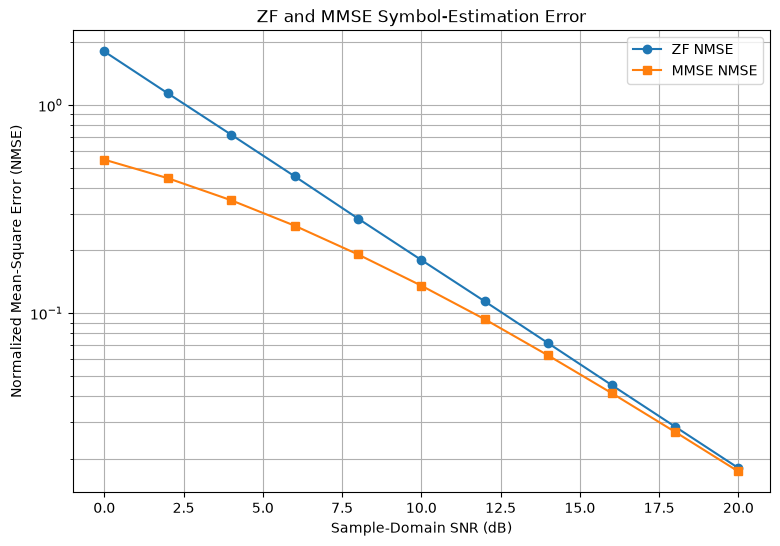

In [12]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    snr_db_values,
    zf_nmse_values,
    marker="o",
    label="ZF NMSE"
)

plt.semilogy(
    snr_db_values,
    mmse_nmse_values,
    marker="s",
    label="MMSE NMSE"
)

plt.xlabel("Sample-Domain SNR (dB)")
plt.ylabel("Normalized Mean-Square Error (NMSE)")
plt.title("ZF and MMSE Symbol-Estimation Error")
plt.grid(True, which="both")
plt.legend()

plt.savefig(
    "../results/zf_mmse_nmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## BER Comparison

Although MMSE produces lower symbol-estimation error, the hard-decision BER is identical to that of zero-forcing in this experiment.

With perfect channel knowledge, the MMSE output can be expressed as a positive real scaling of the zero-forcing estimate. This scaling changes the magnitude of each estimated symbol but does not change its quadrant.

Since the QPSK detector used here determines each bit from the signs of the in-phase and quadrature components, both equalizers therefore make the same hard decisions for every received symbol.

This result illustrates an important distinction between symbol-estimation accuracy and hard-decision bit-error performance.

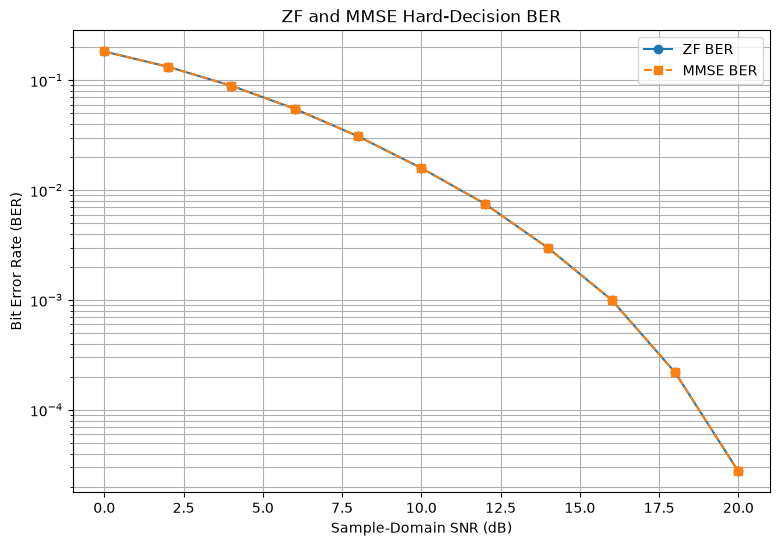

In [13]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    snr_db_values,
    zf_ber_values,
    marker="o",
    label="ZF BER"
)

plt.semilogy(
    snr_db_values,
    mmse_ber_values,
    marker="s",
    linestyle="--",
    label="MMSE BER"
)

plt.xlabel("Sample-Domain SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("ZF and MMSE Hard-Decision BER")
plt.grid(True, which="both")
plt.legend()

plt.savefig(
    "../results/zf_mmse_ber_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
nmse_improvement_percent = (
    100
    * (zf_nmse_values - mmse_nmse_values)
    / zf_nmse_values
)

print(
    f"{'SNR (dB)':>8} "
    f"{'MMSE NMSE improvement':>24}"
)

print("-" * 35)

for snr_db, improvement in zip(
    snr_db_values,
    nmse_improvement_percent
):
    print(
        f"{snr_db:8.1f} "
        f"{improvement:23.2f}%"
    )

print()
print(
    "Maximum MMSE NMSE improvement:",
    f"{np.max(nmse_improvement_percent):.2f}%"
)

print(
    "Minimum MMSE NMSE improvement:",
    f"{np.min(nmse_improvement_percent):.2f}%"
)

SNR (dB)    MMSE NMSE improvement
-----------------------------------
     0.0                   69.77%
     2.0                   60.90%
     4.0                   51.59%
     6.0                   42.10%
     8.0                   32.77%
    10.0                   24.71%
    12.0                   17.95%
    14.0                   12.69%
    16.0                    8.50%
    18.0                    5.65%
    20.0                    3.74%

Maximum MMSE NMSE improvement: 69.77%
Minimum MMSE NMSE improvement: 3.74%


## Results and Interpretation

This experiment compared zero-forcing (ZF) and minimum mean-square error (MMSE) frequency-domain equalization for QPSK/OFDM transmission through the same frequency-selective multipath channel used in the previous experiments.

Both equalizers were evaluated using identical transmitted data, channel conditions, and AWGN realizations so that their performance could be compared directly.

At the 10 dB comparison point, ZF produced a normalized mean-square symbol-estimation error of approximately 0.182, while MMSE reduced this to approximately 0.137. The corresponding MMSE improvement was about 24.8%. The constellation diagrams illustrate the reason for this difference: ZF completely inverts the channel and therefore strongly amplifies noise on weak subcarriers, whereas MMSE regularizes the channel inversion and limits this noise enhancement.

Across the full SNR sweep, MMSE produced lower NMSE than ZF at every tested SNR. The improvement was largest at low SNR, reaching approximately 69.8% at 0 dB. As the SNR increased, the difference decreased, falling to approximately 3.7% at 20 dB. This behavior is expected because the MMSE regularization term becomes progressively less important as the noise power decreases, causing MMSE to approach the ZF solution.

Despite the difference in symbol-estimation error, ZF and MMSE produced identical hard-decision QPSK bit-error rates at every tested SNR. Under perfect channel knowledge, the MMSE estimate is a positive real scaling of the corresponding ZF estimate. This scaling changes symbol magnitude but not the signs of the in-phase and quadrature components. Because the QPSK detector used in this experiment depends only on those signs, the detected bits remain identical.

The experiment therefore demonstrates an important distinction between symbol-estimation quality and hard-decision detection performance. MMSE provides a more accurate estimate of the transmitted complex symbols, particularly when noise is significant, even when that improvement does not produce a lower hard-decision BER for this specific QPSK detector and perfect-channel-knowledge model.

A later experiment can extend this comparison to imperfect channel estimation, where errors in the estimated channel response make the receiver more realistic and can change the relative behavior of the equalizers.

In [15]:
# Final ZF/MMSE experiment validation

assert len(snr_db_values) == len(zf_nmse_values)
assert len(snr_db_values) == len(mmse_nmse_values)
assert len(snr_db_values) == len(zf_ber_values)
assert len(snr_db_values) == len(mmse_ber_values)

# All calculated performance values must be finite
assert np.all(np.isfinite(zf_nmse_values))
assert np.all(np.isfinite(mmse_nmse_values))
assert np.all(np.isfinite(zf_ber_values))
assert np.all(np.isfinite(mmse_ber_values))

# MMSE should outperform ZF in symbol-estimation error
assert np.all(mmse_nmse_values < zf_nmse_values)

# Under the assumptions of this experiment,
# both equalizers must make identical hard decisions
assert np.array_equal(
    zf_ber_values,
    mmse_ber_values
)

# Error should decrease as SNR increases
assert np.all(np.diff(zf_nmse_values) < 0)
assert np.all(np.diff(mmse_nmse_values) < 0)
assert np.all(np.diff(zf_ber_values) < 0)

# MMSE advantage should shrink toward high SNR
assert nmse_improvement_percent[0] > nmse_improvement_percent[-1]

print("ZF/MMSE equalization experiment validation: PASSED")
print(
    "Maximum MMSE NMSE improvement:",
    f"{np.max(nmse_improvement_percent):.2f}%"
)
print(
    "Minimum MMSE NMSE improvement:",
    f"{np.min(nmse_improvement_percent):.2f}%"
)
print(
    "ZF/MMSE BER arrays identical:",
    np.array_equal(zf_ber_values, mmse_ber_values)
)

ZF/MMSE equalization experiment validation: PASSED
Maximum MMSE NMSE improvement: 69.77%
Minimum MMSE NMSE improvement: 3.74%
ZF/MMSE BER arrays identical: True
